In [13]:
import os
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, List
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import faiss
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_classic.schema import Document
from langchain_google_genai import ChatGoogleGenerativeAI

In [3]:
import os
from dotenv import load_dotenv

load_dotenv()

True

In [6]:
llm= ChatGoogleGenerativeAI(
    model= "gemini-3.6-flash",
    temperature= 0
)
embeddings= HuggingFaceEmbeddings(model="sentence-transformers/all-MiniLM-L6-v2")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2144.81it/s]


In [7]:
class AgentState(TypedDict):
    question: str
    documents: List[Document]
    answer: str
    needs_retrieval: bool

In [8]:
llm

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-google-genai': '4.4.0'}}, profile={'name': 'Gemini 3.6 Flash', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'medium'}, google_api_key=SecretStr('**********'), model='gemini-3.6-flash', temperature=0.0, client=<google.genai.client.Client object at 0x0000021EDD3B3490>, default_metadata=(), model_kwargs={})

In [9]:
embeddings

HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2', cache_folder=None, model_kwargs={}, encode_kwargs={}, query_encode_kwargs={}, multi_process=False, show_progress=False)

In [11]:
documents= ""

In [ ]:
vector_store= faiss.from(documents, embeddings)
retriever= vector_store.as_retriever(k=3)

TypeError: Document.__init__() takes 2 positional arguments but 3 were given

In [18]:
def decide_retrieval(state: AgentState) -> AgentState:
    """
    Decide we need to retrieve based on the query
    """ 

    retrieval_keywords= ["what", "how", "explain", "describe", "tell me"]

    needs_retrieval= any(keyword in question.lower() for keyword in retrieval_keywords)

    return {**state, "needs_retrieval": needs_retrieval}

In [19]:
def retrieve_documents(state: AgentState) -> AgentState:
    """
    Retrieve relevant documents based on the question
    """

    question= state["question"]
    documents= retriever.invoke(question)

    return {**state, "documents": documents}

In [16]:
def generate_answer(state: AgentState) -> AgentState:
    """
    Generate an aswer using the retrieved documents or direct response
    """

    question= state["question"]
    documents= state.get("documents", [])

    if documents:
        context= "\n\n".join([doc.page_content for doc in documents])
        prompt= f"""Based on the following question answer the question

        context: {context}
        question: {question}
        Answer:
        """

    else:
        prompt= f"Answer the following question:  {question}"

    response= llm.invoke(prompt)
    answer= response.content

    return {**state, "answer": answer}

In [17]:
def should_retrieve(state: AgentState) -> str:
    """
    Determine the next step based on the retrieval decision
    """
    if state["needs_retrieval"]:
        return "retrieve"
    else:
        "generate"

In [23]:
graph= StateGraph(AgentState)

graph.add_node("decide", decide_retrieval)
graph.add_node("retrieve", retrieve_documents)
graph.add_node("generate", generate_answer)

graph.add_edge(START, "decide")

graph.add_conditional_edges(
    "decide",
    should_retrieve,
    {
        "retrieve": "retrieve",
        "generate": "generate"
    }
)
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)

app= graph.compile()

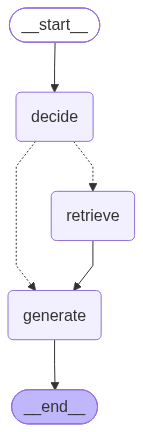

In [24]:
from IPython.display import display, Image

display(Image(app.get_graph().draw_mermaid_png()))